# Relatedness results, errors and inference
The final test was released once after the full validation-selected policy and real-text inference proof were frozen. This notebook reads its saved aggregate report only. Detailed residual analysis below uses development labels, never reopens final gold and never changes model selection.

The learned model improved rating MAE but failed its heldout ranking objective against character overlap.

In [1]:
from pathlib import Path
import sys,json,math,hashlib,time,copy
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib','inline')
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
PROCESSED=ROOT/'data/processed/semrel-lf-v1'
CACHE=ROOT/'data/features/afro-xlmr-v1'
FIGURES=ROOT/'assets/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def show(fig,name):
    fig.tight_layout(pad=1.5,w_pad=3)
    fig.savefig(FIGURES/name,dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def report(name):return json.loads((ROOT/'docs'/name).read_text(encoding='utf-8'))

In [2]:
final=report('final-test-v1.json')
model=pd.DataFrame(final['test']['languages']).T
baseline=pd.DataFrame(final['baseline']['languages']).T
comparison=model[['spearman','pearson','mae','rows']].add_prefix('model_')
for metric in ('spearman','pearson','mae'):comparison['baseline_'+metric]=baseline[metric]
comparison['Spearman_delta']=comparison['model_spearman']-comparison['baseline_spearman']
comparison['MAE_delta']=comparison['model_mae']-comparison['baseline_mae']
display(comparison)
display(pd.DataFrame({'learned_model':{k:final['test'][k] for k in ('macro_spearman','macro_pearson','macro_mae')},'character_baseline':{k:final['baseline'][k] for k in ('macro_spearman','macro_pearson','macro_mae')}}))
assert final['selection_unchanged']

,model_spearman,model_pearson,model_mae,model_rows,baseline_spearman,baseline_pearson,baseline_mae,Spearman_delta,MAE_delta
amh,0.672556,0.690069,0.152936,171.0,0.727376,0.716692,0.241569,-0.054820,-0.088633
hau,0.504991,0.513731,0.190592,603.0,0.530506,0.516433,0.251446,-0.025514,-0.060853
kin,0.468377,0.475506,0.160385,222.0,0.488252,0.463998,0.224057,-0.019875,-0.063672


,learned_model,character_baseline
macro_spearman,0.548641,0.582045
macro_pearson,0.559768,0.565708
macro_mae,0.167971,0.239024


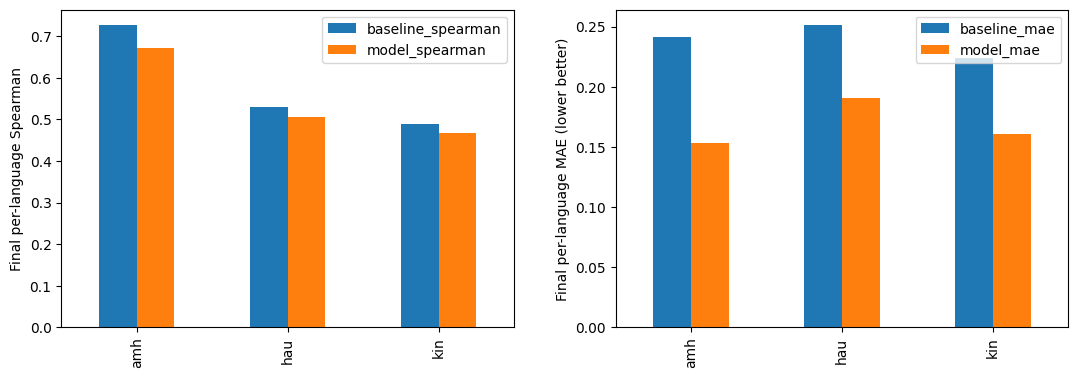

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
comparison[['baseline_spearman','model_spearman']].plot.bar(ax=axes[0]);axes[0].set(ylabel='Final per-language Spearman',xlabel='')
comparison[['baseline_mae','model_mae']].plot.bar(ax=axes[1]);axes[1].set(ylabel='Final per-language MAE (lower better)',xlabel='')
show(fig,'sts_final_rank_and_MAE.png')

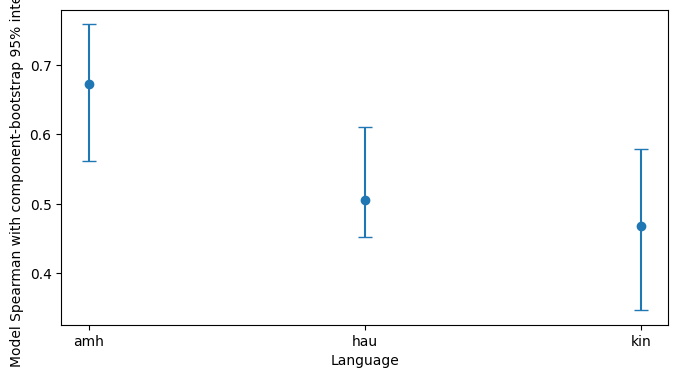

,valid_resamples,macro_interval,paired_delta_interval,components
0,1000,"[0.4927333563131866, 0.6054622089777756]","[-0.09107223228349591, 0.025225418182357993]","{'amh': 171, 'hau': 169, 'kin': 212}"


In [4]:
uncertainty=final['uncertainty']
intervals=uncertainty['per_language_spearman_95_percentile']
point=model['spearman'].to_numpy();lo=np.array([intervals[l][0] for l in model.index]);hi=np.array([intervals[l][1] for l in model.index])
fig,ax=plt.subplots(figsize=(7,4));ax.errorbar(model.index,point,yerr=[point-lo,hi-point],fmt='o',capsize=5)
ax.set(ylabel='Model Spearman with component-bootstrap 95% interval',xlabel='Language')
show(fig,'sts_component_uncertainty.png')
display(pd.DataFrame([{'valid_resamples':uncertainty['valid_macro_resamples'],'macro_interval':uncertainty['macro_spearman_95_percentile'],'paired_delta_interval':uncertainty['paired_macro_spearman_delta_95_percentile'],'components':uncertainty['components_per_language']}]))

The paired macro-Spearman interval spans zero. The point estimate is lower for the learned model in every language, while MAE is lower in every language. These are different objectives; better calibration error did not establish better ranking. Hausa's large reused sentence component limits the independence of the bootstrap.

## Development residuals and calibration
The following analysis uses the existing validation cohort and saved frozen model. Counts below five are suppressed in binned summaries. No text, IDs, raw pair rows or final test targets are displayed.

In [5]:
import torch
from src.models.train import load_split,predict_features
torch.set_num_threads(2)
x,y,languages,_,_=load_split(CACHE,PROCESSED,'dev')
selected=torch.load(ROOT/'models/selected-v1/selected.pt',map_location='cpu',weights_only=True)
base=torch.load(ROOT/'models/selected-v1/baseline.pt',map_location='cpu',weights_only=True)
p=predict_features(selected,x);b=predict_features(base,x)
residual=pd.DataFrame({'language':languages,'target':y,'prediction':p,'baseline':b,'absolute_error':np.abs(y-p),'baseline_absolute_error':np.abs(y-b)})
residual['target_bin']=pd.cut(residual['target'],bins=np.linspace(0,1,6),include_lowest=True)
binned=residual.groupby(['language','target_bin'],observed=True).agg(count=('target','size'),mean_target=('target','mean'),mean_prediction=('prediction','mean'),mean_baseline=('baseline','mean'),MAE=('absolute_error','mean'),baseline_MAE=('baseline_absolute_error','mean')).reset_index()
binned=binned[binned['count']>=5]
display(binned)

,language,target_bin,count,mean_target,mean_prediction,mean_baseline,MAE,baseline_MAE
0,amh,"(-0.001, 0.2]",7,0.142857,0.131870,0.038250,0.069272,0.104607
1,amh,"(0.2, 0.4]",24,0.298333,0.253872,0.155959,0.147219,0.172127
2,amh,"(0.4, 0.6]",32,0.499687,0.468563,0.280657,0.110674,0.224030
3,amh,"(0.6, 0.8]",23,0.680000,0.675805,0.380075,0.126539,0.302658
4,amh,"(0.8, 1.0]",9,0.861111,0.768442,0.486344,0.132956,0.374767
5,hau,"(-0.001, 0.2]",30,0.076333,0.273675,0.229839,0.213635,0.154734
6,hau,"(0.2, 0.4]",45,0.300444,0.386768,0.260050,0.154196,0.064367
7,hau,"(0.4, 0.6]",65,0.495846,0.535935,0.284981,0.148166,0.211520
8,hau,"(0.6, 0.8]",41,0.687073,0.623587,0.313409,0.185687,0.373665
9,hau,"(0.8, 1.0]",31,0.924839,0.691904,0.378785,0.249419,0.546053


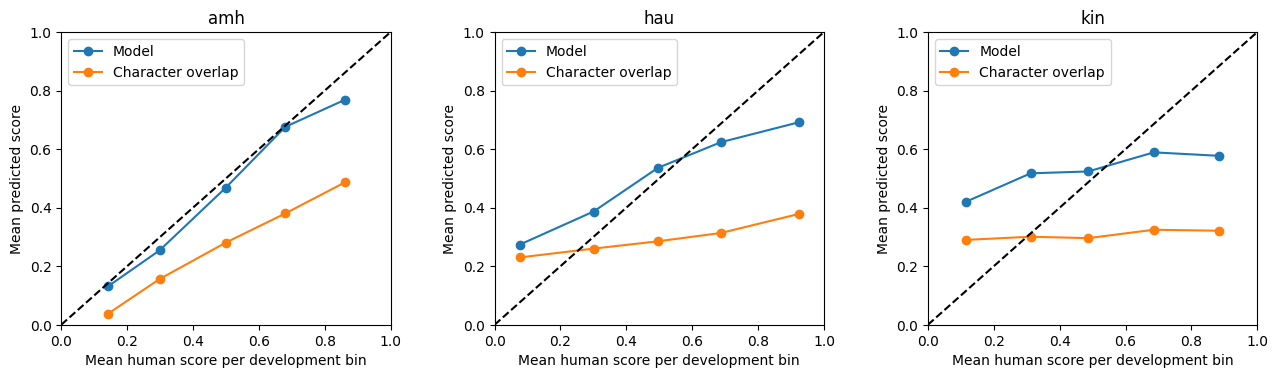

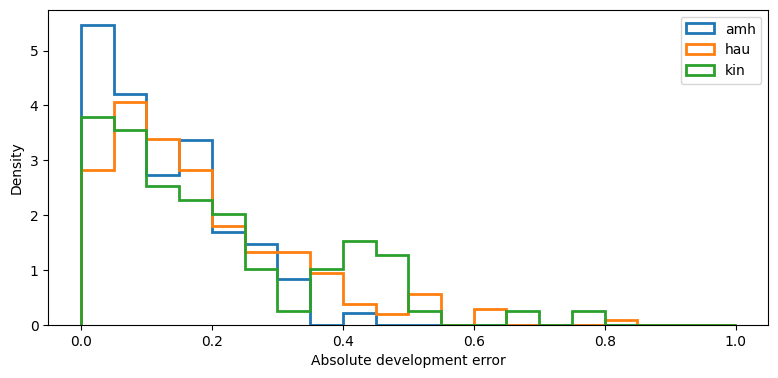

In [6]:
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,(lang,block) in zip(axes,binned.groupby('language')):
    ax.plot(block['mean_target'],block['mean_prediction'],marker='o',label='Model')
    ax.plot(block['mean_target'],block['mean_baseline'],marker='o',label='Character overlap')
    ax.plot([0,1],[0,1],color='black',linestyle='--')
    ax.set(title=lang,xlabel='Mean human score per development bin',ylabel='Mean predicted score',xlim=(0,1),ylim=(0,1));ax.legend()
show(fig,'sts_development_calibration.png')
fig,ax=plt.subplots(figsize=(8,4))
for lang,block in residual.groupby('language'):
    ax.hist(block['absolute_error'],bins=np.linspace(0,1,21),histtype='step',density=True,linewidth=2,label=lang)
ax.set(xlabel='Absolute development error',ylabel='Density');ax.legend();show(fig,'sts_development_error_distribution.png')

## Saved-model real-text inference proof
The private CPU runner loaded the frozen encoder and checkpoint, processed one real training pair per language and reversed each pair. It checked actual text encoding against cached predictions. This verifies mechanics, not new accuracy.

In [7]:
proof=report('actual-inference-proof-v1.json')
display(pd.DataFrame([proof]))
assert proof['cache_prediction_max_difference']<1e-4
assert proof['reversal_max_difference']==0
assert proof['finite_scores_in_unit_interval'] and not proof['accuracy_claim']

,rows,real_source,cache_prediction_max_difference,reversal_max_difference,finite_scores_in_unit_interval,accuracy_claim,test_gold_loaded,checkpoint_sha256,input_sha256,source_manifest_sha256,source_revision,torch,elapsed_seconds
0,6,First training pair per language and reversed ...,1.192093e-07,0.0,True,False,False,293b99ca441829ba9cf36a60ce118384e54c0af8cf791d...,9a99454eebf3ce9e51b9cfaf838c9ec34ddebb729131b9...,7345dd658e93da45293f49150cf25433c137deafd4f0c8...,cfe896d5c928fa3c01a40ac77881839a9bdb0819,2.11.0+cpu,71.188031


The validation-selected checkpoint remains locked despite the final ranking reversal. It is a real learned calibration model with an unsuccessful heldout rank-improvement claim. Further research needs a new prospective study; this observed test cannot be made untouched again.